# Age-Group Comparison of Whole-Brain Network Segregation

## Purpose

This notebook examines whole-brain network segregation in the young and elderly participant groups using the project's existing participant-level segregation results and cohort metadata.

## Goal

The goal is to estimate the difference in mean whole-brain system segregation between the elderly and young groups, adjusting for recorded sex, and quantify the uncertainty around that difference.

The comparison will use the project's primary segregation definition, `seg_z_positive`. The analysis is observational and will be interpreted as exploratory, particularly if individual-level head-motion measurements are unavailable.

## Research Question

**Does whole-brain system segregation differ between the elderly and young groups after adjusting for recorded sex?**

The main comparison will be expressed as the elderly group minus the young group.

## Data Sources

- `data/processed/network_segregation_results.tsv`
- `data/processed/network_segregation_provenance.tsv`
- `data/external/Curvature-FCN-Aging/DATA/cohort_information.tsv`
- `data/interim/participant_alignment_table.csv`

We will first inspect and align these inputs, validate participant identifiers, and establish the eligible analysis sample before examining group differences.

## Import the Required Tools

We will use `pathlib` to locate project files, `pandas` to load and inspect tabular data, and the existing participant-identifier utilities to standardize participant IDs.

We will introduce statistical modeling and plotting libraries later, when we reach those analysis steps, so each import has a clear purpose.

In [1]:
# Import tools for file paths, data handling, and participant identifiers
from pathlib import Path

import numpy as np
import pandas as pd

from lemon_connectivity.identifiers import (
    add_canonical_participant_id,
    validate_canonical_participant_ids,
)

## Locate the Project Root

The project root is the directory containing `pyproject.toml`. We will locate it by checking the current working directory and its parent directories.

All input paths will then be built relative to the project root. This makes the notebook less dependent on where Jupyter was launched.

In [2]:
# Find the repository root so input paths are independent of the working directory
current_path = Path.cwd()

repo_root = next(
    (
        path
        for path in [current_path, *current_path.parents]
        if (path / "pyproject.toml").exists()
    ),
    None,
)

if repo_root is None:
    raise FileNotFoundError(
        "Could not locate the project root containing pyproject.toml."
    )


## Load the Input Data

We will load four project files needed for the age-group comparison:

- **Segregation results:** participant-level whole-brain segregation scores and calculation status.
- **Segregation provenance:** records the segregation definition and details of the calculation.
- **Cohort metadata:** contains each participant's recorded age band, sex, and cohort.
- **Participant alignment audit:** records how participant identifiers and data sources were matched during earlier quality-control steps.

We will preserve participant identifiers as strings to avoid accidentally changing their format. At this stage, we will only load and inspect the data; we will not calculate group differences or fit a statistical model.

All file paths will be constructed relative to the project root identified above.

In [3]:
# Define the input paths relative to the project root
segregation_path = (
    repo_root / "data" / "processed" / "network_segregation_results.tsv"
)

provenance_path = (
    repo_root / "data" / "processed" / "network_segregation_provenance.tsv"
)

cohort_path = (
    repo_root
    / "data"
    / "external"
    / "Curvature-FCN-Aging"
    / "DATA"
    / "cohort_information.tsv"
)

alignment_path = (
    repo_root / "data" / "interim" / "participant_alignment_table.csv"
)

# Load participant-level segregation results
segregation_df = pd.read_csv(
    segregation_path,
    sep="\t",
    dtype={"canonical_id": "string"},
)

# Load the calculation provenance
provenance_df = pd.read_csv(
    provenance_path,
    sep="\t",
)

# Load cohort metadata while preserving raw participant IDs
cohort_df = pd.read_csv(
    cohort_path,
    sep="\t",
    dtype={"sub_id": "string"},
)

# Load the participant alignment audit
alignment_df = pd.read_csv(
    alignment_path,
    dtype={
        "original_subject_id": "string",
        "canonical_id": "string",
    },
)

## Inspect Input Table Dimensions

Before validating and merging the inputs, we will inspect the number of rows and columns in each table. This confirms that the files loaded and gives us an initial view of their sizes.

The participant-level tables are expected to contain participant records, while the provenance table records information about the segregation calculation.

In [4]:
# Confirm that all four input tables loaded and inspect their dimensions
input_tables = {
    "Segregation results": segregation_df,
    "Segregation provenance": provenance_df,
    "Cohort metadata": cohort_df,
    "Participant alignment audit": alignment_df,
}

for name, dataframe in input_tables.items():
    print(f"{name}: {dataframe.shape[0]} rows × {dataframe.shape[1]} columns")

Segregation results: 225 rows × 8 columns
Segregation provenance: 1 rows × 19 columns
Cohort metadata: 225 rows × 4 columns
Participant alignment audit: 225 rows × 10 columns


## Validate the Analysis Inputs

Before aligning participants, we will verify that the required columns are present, participant identifiers are available and unique in each participant-level table, and the recorded segregation definition matches the project's primary definition, `seg_z_positive`.

These checks establish whether the input files are structurally suitable for the planned merge. Any failure will be investigated before proceeding.

In [5]:

# Define the required columns for each input table
required_columns = {
    "segregation_df": {
        "canonical_id",
        "system_segregation",
        "calculation_status",
    },
    "cohort_df": {
        "sub_id",
        "age",
        "sex",
        "cohort",
    },
    "alignment_df": {
        "canonical_id",
        "alignment_status",
    },
    "provenance_df": {
        "segregation_definition",
        "edge_policy_version",
        "within_mean_denominator_rule",
    },
}

# Check that every input contains its required columns
dataframes = {
    "segregation_df": segregation_df,
    "cohort_df": cohort_df,
    "alignment_df": alignment_df,
    "provenance_df": provenance_df,
}

for name, required in required_columns.items():
    missing_columns = required.difference(dataframes[name].columns)

    if missing_columns:
        raise ValueError(
            f"{name} is missing required columns: "
            f"{sorted(missing_columns)}"
        )

# Confirm the provenance table has exactly one record
if len(provenance_df) != 1:
    raise ValueError(
        "Expected exactly one segregation provenance record; "
        f"found {len(provenance_df)}."
    )

# Check that participant IDs are present and unique
participant_tables = {
    "segregation_df": ("canonical_id", segregation_df),
    "cohort_df": ("sub_id", cohort_df),
    "alignment_df": ("canonical_id", alignment_df),
}

for name, (id_column, dataframe) in participant_tables.items():
    participant_ids = dataframe[id_column]

    if (
        participant_ids.isna().any()
        or participant_ids.str.strip().eq("").any()
    ):
        raise ValueError(
            f"{name} contains missing or blank participant IDs."
        )

    if participant_ids.duplicated().any():
        raise ValueError(
            f"{name} contains duplicate participant IDs."
        )

# Read the recorded provenance values
recorded_definition = provenance_df["segregation_definition"].iloc[0]
recorded_edge_policy = provenance_df["edge_policy_version"].iloc[0]
recorded_denominator_rule = (
    provenance_df["within_mean_denominator_rule"].iloc[0]
)

# Confirm the primary segregation definition and edge policy
if recorded_definition != "seg_z_positive":
    raise ValueError(
        f"Unexpected segregation definition: {recorded_definition}"
    )

if recorded_edge_policy != "edge-policy-v1":
    raise ValueError(
        f"Unexpected edge policy: {recorded_edge_policy}"
    )

# Confirm the corrected denominator rule from Issue #58
expected_denominator_rule = "W <= 1e-12 is undefined"

if recorded_denominator_rule != expected_denominator_rule:
    raise ValueError(
        "Unexpected within-mean denominator rule. "
        f"Expected {expected_denominator_rule!r}; "
        f"found {recorded_denominator_rule!r}."
    )

print(f"Recorded segregation definition: {recorded_definition}")
print(f"Recorded edge policy: {recorded_edge_policy}")
print(f"Recorded denominator rule: {recorded_denominator_rule}")


Recorded segregation definition: seg_z_positive
Recorded edge policy: edge-policy-v1
Recorded denominator rule: W <= 1e-12 is undefined


## Create Canonical Participant IDs

The cohort metadata uses `sub_id`, while the segregation results and participant alignment audit use `canonical_id`.

We will use the project's existing identifier utility to add a separate `canonical_id` column to the cohort metadata. The original `sub_id` values will remain unchanged.

We will then validate the canonical IDs before using them to align participants across the input tables.

In [6]:

# Add canonical IDs while preserving the original source identifiers
cohort_df = add_canonical_participant_id(
    cohort_df,
    source_column="sub_id",
    output_column="canonical_id",
)

# Validate the canonical participant IDs
canonical_id_report = validate_canonical_participant_ids(
    cohort_df["canonical_id"]
)


# Stop if any canonical participant IDs fail validation
if (
    canonical_id_report["invalid_canonical_ids"] != 0
    or canonical_id_report["missing_canonical_ids"] != 0
    or canonical_id_report["duplicate_canonical_ids"] != 0
    or not canonical_id_report["all_match_canonical_format"]
    or not canonical_id_report["all_have_expected_prefix"]
    or not canonical_id_report["all_have_expected_length"]
):
    raise ValueError(
        "Canonical participant ID validation failed. "
        "Inspect canonical_id_report before proceeding."
    )

## Check Participant ID Alignment

The segregation results, cohort metadata, and participant alignment audit use `canonical_id` to identify participants consistently.

We will compare the IDs across these three tables to identify any participants present in one table but absent from another. This check will help us establish whether the tables can be safely merged without losing or mismatching participants.

In [7]:
# Validate canonical participant ID formats in all three tables
for name, dataframe in {
    "segregation_df": segregation_df,
    "cohort_df": cohort_df,
    "alignment_df": alignment_df,
}.items():
    id_report = validate_canonical_participant_ids(
        dataframe["canonical_id"]
    )

    if (
        id_report["invalid_canonical_ids"] != 0
        or not id_report["all_match_canonical_format"]
        or not id_report["all_have_expected_prefix"]
        or not id_report["all_have_expected_length"]
    ):
        raise ValueError(
            f"Canonical participant ID format validation failed for {name}."
        )

# Collect the participant IDs from each table
segregation_ids = set(segregation_df["canonical_id"])
cohort_ids = set(cohort_df["canonical_id"])
alignment_ids = set(alignment_df["canonical_id"])

# Compare participant IDs across the three tables
alignment_summary = pd.DataFrame(
    [
        {
            "comparison": "Segregation vs cohort",
            "shared_ids": len(segregation_ids & cohort_ids),
            "only_in_first": len(segregation_ids - cohort_ids),
            "only_in_second": len(cohort_ids - segregation_ids),
        },
        {
            "comparison": "Segregation vs alignment audit",
            "shared_ids": len(segregation_ids & alignment_ids),
            "only_in_first": len(segregation_ids - alignment_ids),
            "only_in_second": len(alignment_ids - segregation_ids),
        },
        {
            "comparison": "Cohort vs alignment audit",
            "shared_ids": len(cohort_ids & alignment_ids),
            "only_in_first": len(cohort_ids - alignment_ids),
            "only_in_second": len(alignment_ids - cohort_ids),
        },
    ]
)

alignment_summary

,comparison,shared_ids,only_in_first,only_in_second
0,Segregation vs cohort,225,0,0
1,Segregation vs alignment audit,225,0,0
2,Cohort vs alignment audit,225,0,0


## Validate Alignment and Merge Participant Data

The participant IDs match across the segregation results, cohort metadata, and alignment audit. Before merging, we will check the recorded alignment statuses and ensure that all three tables have unique participant IDs.

We will then merge the tables using `canonical_id` and validate that the merge preserves the expected participants. This creates one participant-level dataset for the subsequent eligibility checks.

In [8]:
# Check recorded alignment statuses before merging
alignment_status_counts = alignment_df["alignment_status"].value_counts(
    dropna=False
)
alignment_status_counts

alignment_status
matched    225
Name: count, dtype: int64

### Merge the Participant-Level Tables

All 225 participant IDs match across the three tables, and every participant has a `matched` alignment status.

We will merge the cohort metadata with the segregation results and alignment audit using `canonical_id`. We will use inner joins so that only participants present in all three tables are retained, and validate the one-to-one relationships to prevent accidental duplication.

In [9]:

# Record the participant IDs expected in the merged dataset
expected_ids = set(segregation_df["canonical_id"])

# Confirm that every participant has a matched alignment record
if not alignment_df["alignment_status"].eq("matched").all():
    raise ValueError(
        "The alignment audit contains participants without matched status."
    )

# Merge cohort metadata with segregation results and alignment audit
analysis_df = (
    cohort_df
    .merge(
        segregation_df,
        on="canonical_id",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        alignment_df[["canonical_id", "alignment_status"]],
        on="canonical_id",
        how="inner",
        validate="one_to_one",
    )
)

# Confirm that the merge retained every expected participant
merged_ids = set(analysis_df["canonical_id"])

if merged_ids != expected_ids:
    missing_ids = expected_ids - merged_ids
    unexpected_ids = merged_ids - expected_ids

    raise ValueError(
        "The merge changed the expected participant set. "
        f"Missing participants: {len(missing_ids)}; "
        f"unexpected participants: {len(unexpected_ids)}."
    )

print(
    f"Merged dataset: {analysis_df.shape[0]} rows × "
    f"{analysis_df.shape[1]} columns"
)


Merged dataset: 225 rows × 13 columns


### Inspect Analysis Data Completeness and Distributions

Before defining the eligible analysis sample, we will check for missing values in the variables needed for the comparison and summarize the observed segregation calculation statuses, cohort groups, and sex categories.

These checks will help us identify whether any participants need to be excluded and confirm the categories available for the planned model. We will review these results before applying the eligibility rules, including checking that segregation scores are finite.

In [10]:
# Check completeness of the analysis variables
analysis_columns = [
    "cohort",
    "sex",
    "system_segregation",
    "calculation_status",
    "alignment_status",
]

missingness_summary = analysis_df[analysis_columns].isna().sum()
display(missingness_summary)

# Summarize calculation outcomes and participant group distributions
print("Segregation calculation status:")
display(analysis_df["calculation_status"].value_counts(dropna=False))

print("Cohort:")
display(analysis_df["cohort"].value_counts(dropna=False))

print("Sex:")
display(analysis_df["sex"].value_counts(dropna=False))

cohort                0
sex                   0
system_segregation    0
calculation_status    0
alignment_status      0
dtype: int64

Segregation calculation status:


calculation_status
calculated    225
Name: count, dtype: int64

Cohort:


cohort
young      153
elderly     72
Name: count, dtype: int64

Sex:


sex
male      145
female     80
Name: count, dtype: int64

## Define the Eligible Analysis Sample

The analysis will include participants who belong to either the young or elderly cohort, have a recorded sex category of female or male, have a successfully calculated whole-brain segregation score, and have a matched participant alignment status.

We will apply these criteria to the merged dataset and record the numbers of participants retained and excluded. This establishes the analysis sample before we examine group differences or fit the statistical model.

In [11]:

# Identify participants with finite segregation scores
finite_score_mask = np.isfinite(analysis_df["system_segregation"])

# Define the eligibility criteria for the planned analysis
cohort_mask = analysis_df["cohort"].isin(["young", "elderly"])
sex_mask = analysis_df["sex"].isin(["female", "male"])
calculation_mask = analysis_df["calculation_status"].eq("calculated")
alignment_mask = analysis_df["alignment_status"].eq("matched")

eligible_mask = (
    cohort_mask
    & sex_mask
    & calculation_mask
    & alignment_mask
    & finite_score_mask
)

# Count participants failing each individual criterion
exclusion_summary = pd.Series(
    {
        "unrecognized_or_missing_cohort": int((~cohort_mask).sum()),
        "unrecognized_or_missing_sex": int((~sex_mask).sum()),
        "unsuccessful_calculation": int((~calculation_mask).sum()),
        "unmatched_alignment": int((~alignment_mask).sum()),
        "non_finite_segregation_score": int((~finite_score_mask).sum()),
    },
    name="participants_failing_criterion",
)

# Create the eligible analysis dataset
eligible_df = analysis_df.loc[eligible_mask].copy()

# Summarize the analysis sample
eligibility_summary = pd.Series(
    {
        "participants_before_eligibility": len(analysis_df),
        "participants_retained": len(eligible_df),
        "participants_excluded": int((~eligible_mask).sum()),
    }
)

display(exclusion_summary)
display(eligibility_summary)


unrecognized_or_missing_cohort    0
unrecognized_or_missing_sex       0
unsuccessful_calculation          0
unmatched_alignment               0
non_finite_segregation_score      0
Name: participants_failing_criterion, dtype: int64

participants_before_eligibility    225
participants_retained              225
participants_excluded                0
dtype: int64

Participants may fail more than one eligibility criterion; therefore, these counts should not be summed to obtain the total excluded.

### Summarize the Eligible Sample

We will summarize the eligible participants by cohort and recorded sex. This describes the composition of the final analysis sample before statistical modeling, without comparing segregation outcomes between groups.

These counts will also help us verify that both cohort groups and both sex categories are represented in the eligible sample.

In [12]:
# Summarize eligible participants by cohort and sex
eligible_df.groupby(["cohort", "sex"]).size().unstack(fill_value=0)

sex,female,male
cohort,,
elderly,36,36
young,44,109



### Describe Segregation by Age Group

We will summarize whole-brain system segregation separately for the young and elderly groups. For each group, we will report the sample size, mean, standard deviation, and 95% confidence interval for the mean.

These descriptive statistics characterize the observed groups. They are unadjusted summaries; the sex-adjusted OLS model provides the primary estimate of the elderly-minus-young difference.


In [13]:

# Confirm that both age groups have enough participants
cohort_counts = eligible_df["cohort"].value_counts()
required_cohorts = {"young", "elderly"}

if not required_cohorts.issubset(cohort_counts.index):
    raise ValueError(
        "Both young and elderly participants must be present."
    )

if any(cohort_counts[cohort] < 2 for cohort in required_cohorts):
    raise ValueError(
        "Each age group must have at least two participants "
        "to calculate sample standard deviations and "
        "t-based confidence intervals."
    )

# Summarize segregation scores within each age group
group_summary = (
    eligible_df.groupby("cohort")["system_segregation"]
    .agg(n="count", mean="mean", sd="std")
)

# Calculate the 95% t-based confidence interval for each group mean
from scipy.stats import t

group_summary["se"] = (
    group_summary["sd"] / np.sqrt(group_summary["n"])
)

critical_t = group_summary["n"].apply(
    lambda n: t.ppf(0.975, df=n - 1)
)

group_summary["ci_95_lower"] = (
    group_summary["mean"] - critical_t * group_summary["se"]
)
group_summary["ci_95_upper"] = (
    group_summary["mean"] + critical_t * group_summary["se"]
)

group_summary = group_summary.drop(columns="se")
group_summary


,n,mean,sd,ci_95_lower,ci_95_upper
cohort,,,,,
elderly,72,0.661704,0.063976,0.646671,0.676738
young,153,0.667961,0.054986,0.659179,0.676744


### Visualize Segregation by Age Group

A boxplot allows us to compare the distributions of whole-brain system segregation between the young and elderly groups. The median is shown by the line inside each box, while the box represents the interquartile range (the middle 50% of scores). The whiskers show the spread according to the boxplot convention, and individual points beyond them indicate potential outliers.

This plot is descriptive and unadjusted for sex. Potential outliers will be inspected rather than automatically removed.

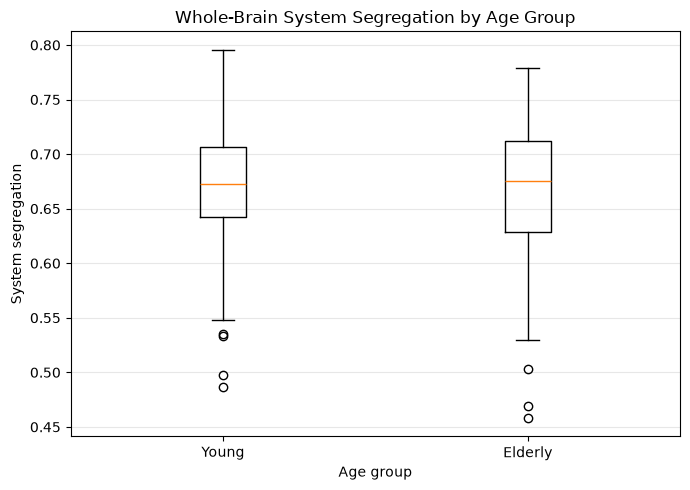

In [14]:
# Import the plotting library
import matplotlib.pyplot as plt

# Arrange segregation scores in the planned age-group order
segregation_by_cohort = [
    eligible_df.loc[
        eligible_df["cohort"] == cohort, "system_segregation"
    ].dropna()
    for cohort in ["young", "elderly"]
]

# Create a boxplot to compare the two distributions
fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(
    segregation_by_cohort,
    tick_labels=["Young", "Elderly"],
    showfliers=True,
)

ax.set_title("Whole-Brain System Segregation by Age Group")
ax.set_xlabel("Age group")
ax.set_ylabel("System segregation")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation:** The boxplot shows a slightly higher median system-segregation score in the elderly group than in the young group (0.6752 vs. 0.6722). The elderly group also has a wider interquartile range (0.0835 vs. 0.0643), indicating greater spread among the middle 50% of scores. However, the elderly group's mean segregation score is slightly lower (0.6617 vs. 0.6680). These descriptive differences show that the distributions differ in their central values and spread, but they are unadjusted for sex and do not establish a statistically significant cohort difference.

### Summarize Final Analysis Sample

We will summarize the number of eligible participants overall and in each cohort before fitting the planned model. These counts will be used to report the analysis sample and document any exclusions.

In [15]:
# Summarize the final eligible sample by cohort
sample_summary = pd.Series(
    {
        "total_eligible": len(eligible_df),
        "young": int(eligible_df["cohort"].eq("young").sum()),
        "elderly": int(eligible_df["cohort"].eq("elderly").sum()),
        "excluded": len(analysis_df) - len(eligible_df),
    },
    name="participants",
)

sample_summary

total_eligible    225
young             153
elderly            72
excluded            0
Name: participants, dtype: int64

## Specify the Statistical Model

We will use an ordinary least squares (OLS) regression to estimate the association between cohort and whole-brain network segregation, adjusting for recorded sex.

The outcome is the participant-level `system_segregation` score. Cohort will be treated as a categorical predictor with `young` as the reference group, and sex will be treated as a categorical adjustment variable with `female` as the reference group.

The primary estimate is the adjusted difference in segregation between the elderly and young groups. We will use HC3 heteroskedasticity-robust standard errors and report the estimate, 95% confidence interval, and two-sided p-value.

This is an observational comparison and will not be interpreted causally. If individual-level head-motion measurements are unavailable, the model will be interpreted as exploratory because residual motion-related confounding cannot be addressed directly.

### Import Statistical Modeling Tools

We will use `statsmodels` to fit the planned OLS regression and calculate HC3 heteroskedasticity-robust standard errors. We will use its formula interface to specify cohort and sex as categorical predictors with explicit reference categories.

We will introduce these tools here so the model implementation remains clear and reproducible.

In [16]:
# Import tools for OLS regression and robust statistical inference
import statsmodels.formula.api as smf

### Fit the Adjusted OLS Model

We will model whole-brain system segregation as a function of cohort and recorded sex. The young cohort and female sex category will serve as the reference groups.

We will use HC3 heteroskedasticity-robust standard errors to account for potential heteroskedasticity. The model will estimate the adjusted elderly-minus-young difference in segregation while accounting for recorded sex.

In [17]:
# Specify the adjusted OLS model with explicit reference categories
model_formula = (
    "system_segregation ~ "
    "C(cohort, Treatment(reference='young')) + "
    "C(sex, Treatment(reference='female'))"
)

# Confirm that both planned cohort and sex categories are present
expected_cohorts = {"young", "elderly"}
expected_sexes = {"female", "male"}

if set(eligible_df["cohort"].unique()) != expected_cohorts:
    raise ValueError(
        "The eligible sample must contain exactly the young "
        "and elderly cohorts."
    )

if set(eligible_df["sex"].unique()) != expected_sexes:
    raise ValueError(
        "The eligible sample must contain exactly female "
        "and male participants."
    )

# Check that the model design matrix has full column rank
design_matrix = smf.ols(
    formula=model_formula,
    data=eligible_df,
).exog

design_rank = np.linalg.matrix_rank(design_matrix)
number_of_parameters = design_matrix.shape[1]

if design_rank < number_of_parameters:
    raise ValueError(
        "The model design matrix is rank-deficient. "
        "Cohort and sex effects cannot be separately estimated "
        "with this design."
    )

print("Model specification checks passed.")
print(f"Design matrix rank: {design_rank}")
print(f"Number of design-matrix columns: {number_of_parameters}")

# Fit the adjusted OLS model using HC3 robust covariance
# and t-based inference for confidence intervals and hypothesis tests
model = smf.ols(
    formula=model_formula,
    data=eligible_df,
).fit(
    cov_type="HC3",
    use_t=True,
)

Model specification checks passed.
Design matrix rank: 3
Number of design-matrix columns: 3


### Validate the Fitted Model

Before interpreting the regression results, we will verify that the fitted model used all eligible participants and that both age groups are represented in the analysis sample. These checks help detect unexpected changes in the sample or model fitting.

In [18]:
# Confirm that both age groups are represented
cohort_counts = eligible_df["cohort"].value_counts()

if not {"young", "elderly"}.issubset(cohort_counts.index):
    raise ValueError(
        "Both young and elderly participants must be present."
    )

# Confirm that the model used all eligible participants
if model.nobs != len(eligible_df):
    raise ValueError(
        "The fitted model did not use all eligible participants. "
        f"Model observations: {int(model.nobs)}; "
        f"eligible participants: {len(eligible_df)}."
    )

# Confirm that the estimated age-group difference is finite
elderly_term = "C(cohort, Treatment(reference='young'))[T.elderly]"
elderly_difference = model.params[elderly_term]

if not np.isfinite(elderly_difference):
    raise ValueError(
        "The estimated elderly-minus-young difference is not finite."
    )

print("Model validation passed.")
print(f"Eligible participants: {len(eligible_df)}")
print(f"Model observations: {int(model.nobs)}")
print("Both age groups are represented.")
print(f"Elderly-minus-young coefficient: {elderly_difference:.6f}")

Model validation passed.
Eligible participants: 225
Model observations: 225
Both age groups are represented.
Elderly-minus-young coefficient: -0.004286


### Examine Residuals Versus Fitted Values

Residuals are the differences between observed and model-predicted segregation scores. Plotting residuals against fitted values helps us inspect whether the residuals show systematic patterns or changes in spread that may indicate limitations in the model.

This is a diagnostic check, not a test of whether the age-group difference is statistically significant.

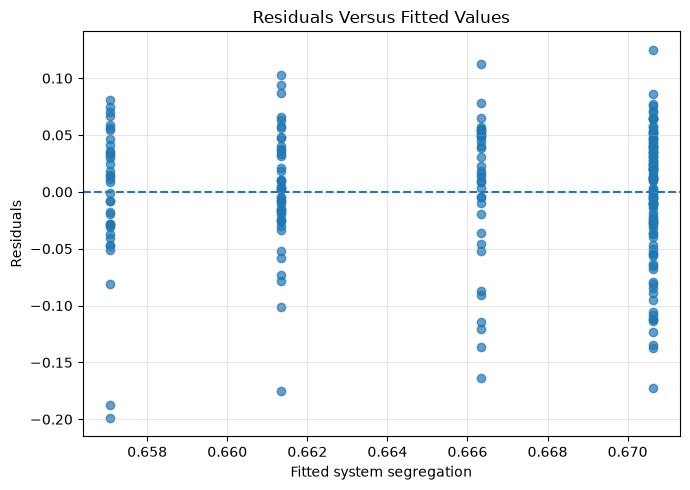

In [19]:
# Obtain fitted values and residuals from the adjusted model
fitted_values = model.fittedvalues
residuals = model.resid

# Plot residuals against fitted values
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(fitted_values, residuals, alpha=0.7)
ax.axhline(0, linestyle="--")

ax.set_title("Residuals Versus Fitted Values")
ax.set_xlabel("Fitted system segregation")
ax.set_ylabel("Residuals")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation:** The residuals appear reasonably balanced around zero, with no obvious systematic pattern or strong change in vertical spread across the fitted values. This is visually reassuring, although the plot alone cannot establish that the homoscedasticity assumption is fully satisfied. The vertical columns are expected because the model uses categorical age group and sex predictors. HC3 robust standard errors were used to make inference more robust to possible heteroscedasticity.

### Examine the Normality of Residuals

A quantile–quantile (Q–Q) plot compares the observed residual distribution with the distribution expected under normality. Points close to the reference line indicate approximate agreement, while systematic departures—especially at the tails—may indicate skewness or unusually extreme residuals.

The Q–Q plot is a diagnostic aid, not a standalone pass-or-fail test. We will use it alongside the other model diagnostics.

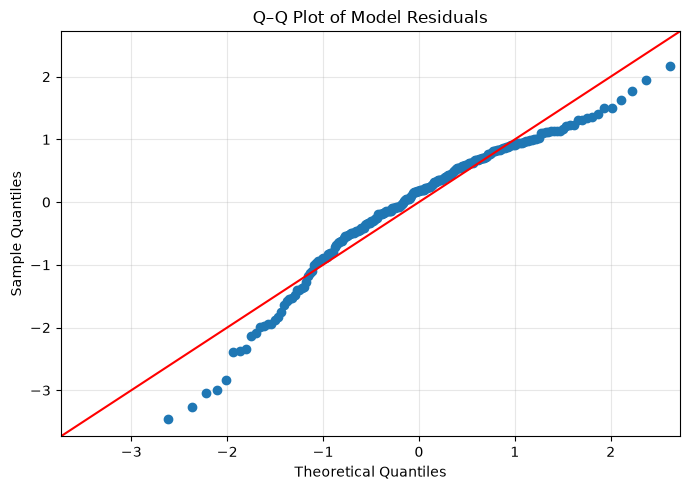

In [20]:
# Import the Q-Q plot function
import statsmodels.api as sm

# Compare the residuals with a normal distribution
fig, ax = plt.subplots(figsize=(7, 5))

sm.qqplot(residuals, line="45", fit=True, ax=ax)

ax.set_title("Q–Q Plot of Model Residuals")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Quantify Residual Distribution Shape

We will calculate the skewness and excess kurtosis of the model residuals to quantify departures from a normal distribution. Skewness describes the asymmetry of the residual distribution, while excess kurtosis describes how its tails compare with those of a normal distribution, for which excess kurtosis is zero.

These statistics complement the Q–Q plot; they do not by themselves determine whether the model is appropriate.

In [21]:

# Calculate the skewness and excess kurtosis of model residuals
residual_skewness = residuals.skew()
residual_excess_kurtosis = residuals.kurtosis()

print(f"Residual skewness: {residual_skewness:.4f}")
print(f"Residual excess kurtosis: {residual_excess_kurtosis:.4f}")


Residual skewness: -0.9595
Residual excess kurtosis: 1.0576


**Interpretation:** The residual skewness of −0.9595 suggests negative skewness, while the excess kurtosis of 1.0576 suggests heavier tails than expected under a normal distribution. These statistics indicate a possible departure from residual normality. The Q–Q plot should be inspected to determine whether deviations are concentrated in the tails or occur more broadly. These findings do not automatically invalidate the OLS model, but they motivate further diagnostic checks.

### Identify Potentially Influential Observations

Cook's distance measures how much the fitted regression estimates may change when an observation is removed. Larger values identify observations that may have greater influence on the model. We will inspect the distribution of Cook's distances and flag observations for review, without automatically excluding them.

Screening threshold (4/n): 0.01778
Observations above threshold: 10
Maximum Cook's distance: 0.07735


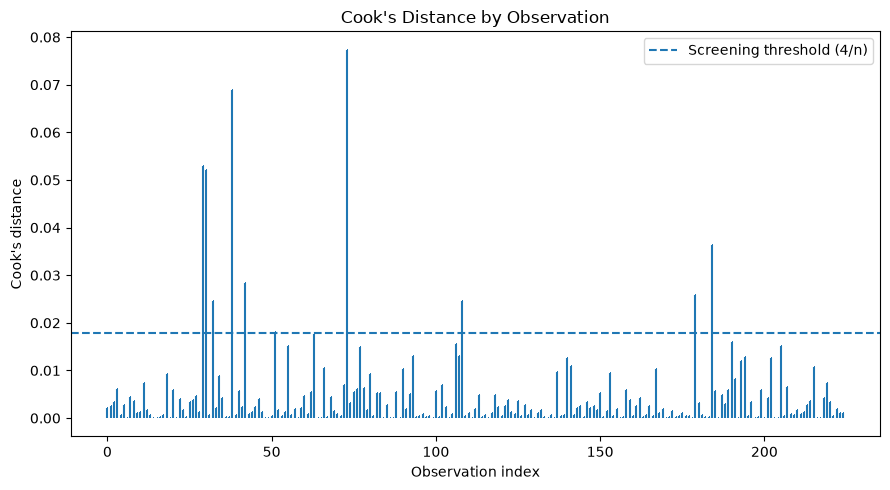

In [22]:
# Calculate influence diagnostics from the fitted OLS model
influence = model.get_influence()
cooks_distance = influence.cooks_distance[0]

# Use 4/n as a screening threshold, not an automatic exclusion rule
cook_threshold = 4 / model.nobs
potentially_influential = cooks_distance > cook_threshold

print(f"Screening threshold (4/n): {cook_threshold:.5f}")
print(
    "Observations above threshold: "
    f"{int(potentially_influential.sum())}"
)
print(f"Maximum Cook's distance: {cooks_distance.max():.5f}")

# Plot Cook's distance for all observations
fig, ax = plt.subplots(figsize=(9, 5))

ax.stem(
    np.arange(len(cooks_distance)),
    cooks_distance,
    markerfmt=",",
    basefmt=" ",
)

ax.axhline(
    cook_threshold,
    linestyle="--",
    label="Screening threshold (4/n)",
)

ax.set_title("Cook's Distance by Observation")
ax.set_xlabel("Observation index")
ax.set_ylabel("Cook's distance")
ax.legend()

plt.tight_layout()
plt.show()

**Interpretation:** Ten observations exceeded the \(4/n\) screening threshold, and the maximum Cook’s distance was 0.07735. These observations are flagged for review because they may have greater influence on the fitted model. However, exceeding the threshold does not establish that an observation is problematic, and no observations will be automatically excluded. The influence diagnostics will be considered alongside the model results before deciding whether a sensitivity analysis is needed.

### Examine Leverage

Leverage measures how unusual each observation's predictor values are relative to the rest of the sample. Observations with higher leverage may have greater potential to influence the fitted regression model.

We will compare the observed leverage values with a commonly used screening guideline of \(2p/n\), where \(p\) is the number of estimated model parameters, including the intercept, and \(n\) is the sample size. This is a screening guideline, not an automatic exclusion rule.

In [23]:
# Extract leverage values from the fitted model
leverage = influence.hat_matrix_diag

# Calculate the screening threshold
n = int(model.nobs)
p = int(model.df_model) + 1
leverage_threshold = 2 * p / n

# Count observations above the threshold
high_leverage = leverage > leverage_threshold

print(f"Number of observations: {n}")
print(f"Estimated model parameters (p): {p}")
print(f"Leverage screening threshold (2p/n): {leverage_threshold:.5f}")
print(f"Observations above threshold: {int(high_leverage.sum())}")
print(f"Maximum leverage: {leverage.max():.5f}")

Number of observations: 225
Estimated model parameters (p): 3
Leverage screening threshold (2p/n): 0.02667
Observations above threshold: 0
Maximum leverage: 0.01896


**Interpretation:** No observations exceeded the leverage screening threshold of 0.02667, and the maximum leverage was 0.01896. Therefore, no observations were flagged for unusually high leverage using this guideline. However, ten observations exceeded the Cook's distance screening threshold. These results will be interpreted together, and no observations will be excluded solely because they exceed a screening threshold.

### Report the Adjusted Cohort Difference

After the analysis decision has been documented in the project plan, we will extract the adjusted elderly-minus-young difference in whole-brain system segregation from the fitted model.

The report will include the estimated difference, HC3 robust standard error, 95% confidence interval, and two-sided p-value. We will also report the number of participants included in the model and interpret the estimate in the context of the study's observational design and any limitations in head-motion adjustment.

In [24]:

# Identify the model coefficient for elderly versus young
cohort_term = (
    "C(cohort, Treatment(reference='young'))[T.elderly]"
)

# Confirm that the expected coefficient exists
if cohort_term not in model.params.index:
    raise ValueError(
        "The expected elderly-minus-young coefficient was not found."
    )

# Extract the adjusted cohort difference and its uncertainty
confidence_interval = model.conf_int().loc[cohort_term]

# Assemble the planned results into a compact table
model_results = pd.DataFrame(
    [
        {
            "comparison": "Elderly minus young",
            "adjusted_difference": model.params[cohort_term],
            "hc3_robust_se": model.bse[cohort_term],
            "ci_95_lower": confidence_interval.iloc[0],
            "ci_95_upper": confidence_interval.iloc[1],
            "p_value_two_sided": model.pvalues[cohort_term],
            "n_total": int(model.nobs),
            "n_young": int(eligible_df["cohort"].eq("young").sum()),
            "n_elderly": int(eligible_df["cohort"].eq("elderly").sum()),
        }
    ]
)

# Check that the estimated effect and its uncertainty are finite
numeric_results = model_results[
    [
        "adjusted_difference",
        "hc3_robust_se",
        "ci_95_lower",
        "ci_95_upper",
        "p_value_two_sided",
    ]
]

if not np.isfinite(numeric_results.to_numpy()).all():
    raise ValueError(
        "The model results contain missing or non-finite values."
    )

# Display the validated results
model_results


,comparison,adjusted_difference,hc3_robust_se,ci_95_lower,ci_95_upper,p_value_two_sided,n_total,n_young,n_elderly
0,Elderly minus young,-0.004286,0.00899,-0.022003,0.01343,0.633997,225,153,72


**Interpretation:** The adjusted elderly-minus-young difference in whole-brain network segregation was −0.0043 (HC3 robust SE = 0.0090; 95% CI: −0.0220 to 0.0134; two-sided *p* = 0.634). The confidence interval includes zero, and the analysis did not find statistically significant evidence of a difference in mean segregation between the elderly and young groups after adjustment for recorded sex. This result does not establish that the groups have identical mean segregation.

The analysis included 225 participants: 153 young and 72 elderly, with no exclusions under the predefined eligibility criteria. Because this is a cross-sectional observational comparison, the estimated difference does not represent within-person change with aging and cannot establish causality. Individual-level head-motion adjustment was unavailable, so the findings should be interpreted as exploratory because residual motion-related confounding could not be directly addressed.

### Visualize the Adjusted Cohort Difference

This plot displays the adjusted difference in whole-brain network segregation between elderly and young participants, with its 95% confidence interval. The vertical reference line at zero represents no adjusted cohort difference. If the confidence interval crosses zero, the data are compatible with both negative and positive differences at the 95% confidence level.

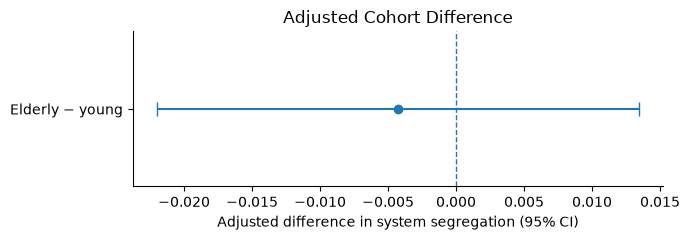

In [25]:
# Import the plotting library
import matplotlib.pyplot as plt

# Extract the adjusted difference and confidence interval
estimate = model_results.loc[0, "adjusted_difference"]
ci_lower = model_results.loc[0, "ci_95_lower"]
ci_upper = model_results.loc[0, "ci_95_upper"]

# Plot the estimate and its 95% confidence interval
fig, ax = plt.subplots(figsize=(7, 2.5))

ax.errorbar(
    estimate,
    0,
    xerr=[[estimate - ci_lower], [ci_upper - estimate]],
    fmt="o",
    capsize=5,
)

# Mark the value corresponding to no cohort difference
ax.axvline(0, linestyle="--", linewidth=1)

ax.set_yticks([0])
ax.set_yticklabels(["Elderly − young"])
ax.set_xlabel("Adjusted difference in system segregation (95% CI)")
ax.set_title("Adjusted Cohort Difference")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

**Interpretation:** The point estimate lies slightly to the left of zero, indicating that the adjusted mean system-segregation score was lower in the elderly group than in the young group. However, the 95% confidence interval crosses zero, indicating substantial uncertainty about the direction and magnitude of the cohort difference. This is consistent with the non-significant two-sided test (*p* = 0.634). The plot does not provide statistically significant evidence of an adjusted difference between the groups.